# Myopic policy examples

This notebook shows two current `MyopicPayoffPolicy` workflows:

- one verbose simulator step from a random directed graph with 10 nodes
- many episodes from empty 10-node networks, with social welfare plotted over time


## Imports and helpers


In [1]:
import sys
from pathlib import Path

import igraph as ig
import matplotlib.pyplot as plt
import numpy as np

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.core.agent import Agent
from network_creation.core.environment import Environment
from network_creation.core.graph import create_empty_graph
from network_creation.core.model import SchedulingMode
from network_creation.core.simulator import Simulator
from network_creation.observers import (
    ActionPrintObserver,
    SocialWelfareObserver,
    StateHistoryObserver,
)
from network_creation.plotting.episode_series import plot_episode_series_observer
from network_creation.plotting.graph_history import (
    build_circle_layout,
    plot_graph_history,
)
from network_creation.policies.myopic_payoff import MyopicPayoffPolicy

In [2]:
def make_myopic_agents(
    n_nodes: int,
    radius: int,
    seed_start: int,
    **policy_kwargs,
) -> tuple[Agent, ...]:
    return tuple(
        Agent(
            id=node_id,
            radius=radius,
            policy=MyopicPayoffPolicy(
                seed=seed_start + 1_000 + node_id,
                **policy_kwargs,
            ),
            seed=seed_start + node_id,
        )
        for node_id in range(n_nodes)
    )


In [3]:
def get_linking_game_welfare(group_size, link_cost, per_link_benefit, decay):
    return {
        "max": per_link_benefit
        * (
            group_size
            + 2 * (group_size - 1) * decay
            + (group_size - 1) * (group_size - 2) * (decay**2)
        )
        - link_cost * (group_size - 1),
        "baseline": group_size * per_link_benefit,
    }

In [4]:
n_nodes = 10
policy_kwargs = {
    "link_cost": 20.0,
    "decay": 0.9,
    "per_link_benefit": 10.0,
    "bridge_probability": 0.2,
}

In [5]:
max_baseline_welfare = get_linking_game_welfare(
    group_size=n_nodes,
    link_cost=policy_kwargs["link_cost"],
    per_link_benefit=policy_kwargs["per_link_benefit"],
    decay=policy_kwargs["decay"],
)

## 1. One verbose step on a random 10-node graph

The cell below starts from one random directed graph, runs exactly one simultaneous simulator step with `MyopicPayoffPolicy`, and prints the chosen decisions through `ActionPrintObserver`.


In [6]:
random_graph = ig.Graph.Erdos_Renyi(n=n_nodes, p=0.1, directed=True, loops=False)

verbose_history_observer = StateHistoryObserver(
    observation_frequency=1,
    keep_runs=False,
)
verbose_simulator = Simulator(
    env=Environment(random_graph, seed=11),
    agents=make_myopic_agents(
        n_nodes=n_nodes,
        radius=2,
        seed_start=101,
        **policy_kwargs,
    ),
    mode=SchedulingMode.SIMULTANEOUS,
    max_steps=1,
    rng=np.random.default_rng(211),
    observers=(
        ActionPrintObserver(observation_frequency=1, print_empty_steps=True),
        verbose_history_observer,
    ),
)

print("Initial adjacency matrix:")
print(np.asarray(random_graph.get_adjacency().data, dtype=np.int8))
verbose_simulator.run(n_episodes=1)
verbose_history = verbose_history_observer.get()
print("\nFinal adjacency matrix:")
print(np.asarray(verbose_history.graphs[-1].get_adjacency().data, dtype=np.int8))


Initial adjacency matrix:
[[0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0]
 [0 1 0 0 0 0 0 0 0 0]]
step 0

step 1
  0: DELETE->4 (value={delta=20.0, considered_action=DELETE->4})
  1: PASS
  2: BRIDGE->5
  3: PASS
  4: DELETE->0 (value={delta=20.0, considered_action=DELETE->0})
  5: PASS (value={delta=-19.1, considered_action=ADD->0})
  6: BRIDGE->4
  7: PASS
  8: DELETE->7 (value={delta=11.0, considered_action=DELETE->7})
  9: DELETE->1 (value={delta=11.0, considered_action=DELETE->1})

Final adjacency matrix:
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 1 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


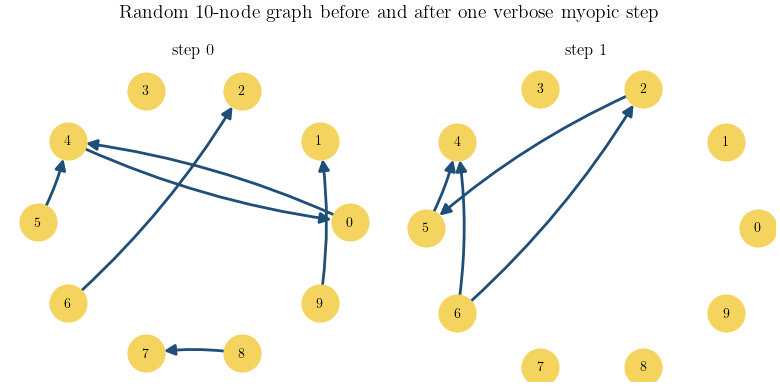

In [7]:
layout = build_circle_layout(n_nodes=n_nodes)
figure, _ = plot_graph_history(
    steps=verbose_history.steps,
    graphs=verbose_history.graphs,
    layout=layout,
    figure_title="Random 10-node graph before and after one verbose myopic step",
    max_cols=2,
)
plt.show()


## 2. Welfare from empty 10-node networks across many episodes

This section starts every episode from the empty directed graph on the same 10 nodes, runs many episodes under `MyopicPayoffPolicy`, and plots the resulting social-welfare trajectories.


In [8]:
welfare_observer = SocialWelfareObserver(
    observation_frequency=1,
    link_cost=policy_kwargs["link_cost"],
    decay=policy_kwargs["decay"],
    per_link_benefit=policy_kwargs["per_link_benefit"],
    aggregations=("mean", "std", "runs"),
    max_welfare=max_baseline_welfare["max"],
    baseline_welfare=max_baseline_welfare["baseline"],
)

welfare_simulator = Simulator(
    env=Environment(create_empty_graph(n_nodes), seed=307),
    agents=make_myopic_agents(
        n_nodes=n_nodes,
        radius=2,
        seed_start=401,
        **policy_kwargs,
    ),
    mode=SchedulingMode.SIMULTANEOUS,
    max_steps=360,
    rng=np.random.default_rng(503),
    observers=(welfare_observer,),
)


In [9]:
welfare_simulator.run(n_episodes=128)

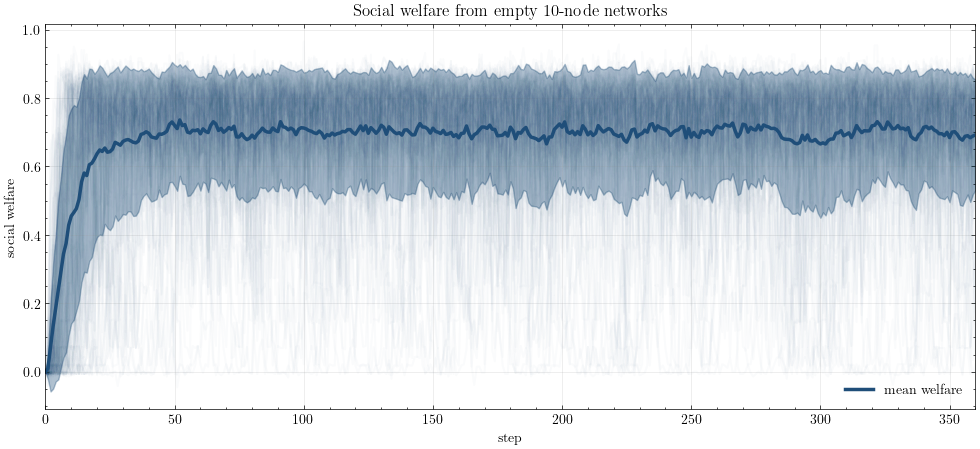

In [10]:
figure, axis = plt.subplots(figsize=(12, 5))
plot_episode_series_observer(
    observer=welfare_observer,
    ax=axis,
    show_runs=True,
    color="#1f4e79",
    band_color="#1f4e79",
    label="mean welfare",
)
axis.set_title(f"Social welfare from empty {n_nodes}-node networks")
plt.show()
